In [25]:
%matplotlib inline

## Audio processing, Video processing and Computer vision
### BSc in Data Science and Engineering - Universidad Carlos III de Madrid
### Academic year 2026/2027

# LAB SESSION 4: IMAGE CLASSIFICATION WITH CNNs (Project featuring Report + Competition)
# Predicting fire risk from satellite images

<center><img src="https://www.uc3m.es/ss/Satellite?blobcol=urldata&blobkey=id&blobtable=MungoBlobs&blobwhere=1371614316787&ssbinary=true" width="400" alt="Universidad Carlos III de Madrid logo"></center>


## Introduction

In this project, we implement deep neural networks to classify fire risk from satellite images.

Note the following two important aspects (among several others you ought to consider during this project):

**Custom network.** `CustomNet` implements the reference CNN from scratch: three convolution/ReLU/max-pooling blocks with 6, 16 and 32 channels, followed by a 120-unit hidden layer and seven output logits. It accepts 224 x 224 RGB images. Use this baseline to experiment with architecture and training improvements.

**Running the notebook.** Start the kernel in this notebook's directory, where `db.zip` is supplied. Use Python 3 with `torch`, `torchvision`, `numpy`, `pandas`, `scikit-image`, `matplotlib`, `scikit-learn` and Pillow installed. The first pretrained AlexNet load downloads its ImageNet weights unless they are already cached. Results and submission files to its own directory under `outputs/`.

### Delivery and submission

The following guidelines and rules must be observed when participating in the CodaBench challenge:

- The challenge will run from October 20 to November 9. Submissions will not be accepted outside this period. The submission **deadline** is **November 9 at 23:59**.

- The submitted project code will be reviewed to verify the validity and reproducibility of the results obtained during the challenge. If the reported results cannot be reproduced using the submitted implementation, the team will be disqualified from the competition and will consequently receive no points for the corresponding component of the final project grade.

The project is worth 1 point toward the final course grade, distributed as follows:

- 45% Report
- 45% System Performance Ranking
- 10% Code

The submitted project code will be reviewed to verify the validity and reproducibility of the results obtained during the challenge. If the reported results cannot be reproduced using the submitted implementation, the team will be disqualified from the competition and will consequently receive no points for the corresponding component of the final project grade.

Additionally, each team (students work in **pairs**) must upload a single `.zip` file to Aula Global containing:

- **Project report**: A short report following the requirements described above.

- **Jupyter notebook**: A notebook containing the implementation of both models, allowing the instructor to review and verify how the proposed solutions were developed.

**IMPORTANT**: Each team member must be responsible for specific improvements or experiments. Furthermore, the report must clearly indicate the contributions of each team member so that individual work can be assessed.

## Part 0: The problem

Before starting, we briefly describe the dataset and the classification task.

The aim of this project that you are embarking on is to develop a neural-network model for fire-risk classification. Forest fires threaten the environment, biodiversity and people's safety. Early detection and propagation modelling can support response planning; this particular assignment **predicts a** dataset's **risk category from a satellite image**, rather than performing fire detection or propagation forecasting.

The seven risk categories are:

- **Very Low:** areas where a fire is very unlikely to start or spread.
- **Low:** areas with low fire risk, although some factors could favour combustion under certain conditions.
- **Moderate:** areas with intermediate risk and potentially favourable conditions for fire spread.
- **High:** areas where a fire is likely to start and spread rapidly.
- **Very High:** areas with particularly favourable conditions for ignition and spread.
- **Non-burnable:** areas without enough combustible material to sustain a fire.
- **Water:** bodies of water.

The source dataset is described in:

Shen, S., Seneviratne, S., Wanyan, X., & Kirley, M. (2023, November). Firerisk: A remote sensing dataset for fire risk assessment with benchmarks using supervised and self-supervised learning. In *2023 International Conference on Digital Image Computing: Techniques and Applications (DICTA)* (pp. 189-196). IEEE.

Further information: [FireRisk repository](https://github.com/CharmonyShen/FireRisk).

For this assignment, a ZIP archive contains 5,861 selected RGB images and CSV files listing each split. The supplied images are **320 x 320 pixels**. The splits contain:

- **Training:** 3,516 images.
- **Validation:** 1,172 images.
- **Test:** 1,173 images.

Each CSV has a header and one row per image with two fields:

- `id`: the image identifier, used to construct the image filename.
- `label`: the class index for training and validation. Test labels are hidden and stored as `-1`.

The class indices and output-column order are fixed:

| Index | Class |
|---:|---|
| 0 | Water |
| 1 | Very Low |
| 2 | Low |
| 3 | Moderate |
| 4 | High |
| 5 | Very High |
| 6 | Non-burnable |

Use training and validation data to develop your system, then generate test predictions. This notebook provides a basic reference pipeline with three main components:

1. Read a custom dataset in PyTorch and implement data augmentation.
2. Build a feedforward convolutional network that maps images to seven class scores.
3. Fine-tune a network pretrained on a large, general-purpose image dataset.


## Part 1: A custom PyTorch dataset. Loading, preprocessing and augmentation

We use `scikit-image` to read and process images and `pandas` to read the CSV files.


In [26]:
from pathlib import Path
import copy
import numbers
import random
import time
import zipfile

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from PIL import Image
from skimage import io, transform, util

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, utils, models

# Install missing dependencies in your chosen environment before running.
# In a notebook, you can use:
# %pip install torch torchvision pandas scikit-image matplotlib scikit-learn pillow

SEED = 42
CLASS_NAMES = ['Water', 'Very Low', 'Low', 'Moderate',
               'High', 'Very High', 'Non-burnable']
NUM_CLASSES = len(CLASS_NAMES)
MAX_TRAIN_SAMPLES = 500  # Set to 0 to use the full training split.
NUM_WORKERS = 0
CUSTOM_EPOCHS = 5
FT_EPOCHS = 5
CUSTOM_LR = 1e-2
FT_LR = 1e-3

# Note: PIXEL_MEAN and PIXEL_STD come directly from AlexNet's
# documentation in PyTorch:
# https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.alexnet.html
PIXEL_MEAN = [0.485, 0.456, 0.406]
PIXEL_STD = [0.229, 0.224, 0.225]

DATA_ARCHIVE = Path('db.zip')
DATA_ROOT = Path('data')
DB_DIR = DATA_ROOT / 'db'
OUTPUT_DIR = Path('outputs') / 'Lab_4_2026_2027'

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything()
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'Class order: {CLASS_NAMES}')

Device: cpu
Class order: ['Water', 'Very Low', 'Low', 'Moderate', 'High', 'Very High', 'Non-burnable']


First, make the dataset archive available in the working directory and extract it locally. If you use Google Colab and the archive is stored in Google Drive, set `COLAB_ARCHIVE_PATH` in the next cell. Otherwise, leave it as `None` and use the local `db.zip`.


In [27]:
"""
# Optional Google Colab setup. Local execution does not import google.colab.
# Example: '/content/drive/MyDrive/your/project/folder/db.zip'
COLAB_ARCHIVE_PATH = #

if DATA_ARCHIVE.is_file():
    print(f"Using local archive: {DATA_ARCHIVE.resolve()}")

elif COLAB_ARCHIVE_PATH is not None:
    from google.colab import drive
    drive.mount("/content/drive")

    DATA_ARCHIVE = Path(COLAB_ARCHIVE_PATH)

    if not DATA_ARCHIVE.is_file():
        raise FileNotFoundError(
            f"Archive not found: {DATA_ARCHIVE}"
        )

    print(f"Using Google Drive archive: {DATA_ARCHIVE}")

else:
    raise FileNotFoundError(
        "Place db.zip in the working directory, "
        "or configure COLAB_ARCHIVE_PATH for Google Colab."
    )
"""

'\n# Optional Google Colab setup. Local execution does not import google.colab.\n# Example: \'/content/drive/MyDrive/your/project/folder/db.zip\'\nCOLAB_ARCHIVE_PATH = #\n\nif DATA_ARCHIVE.is_file():\n    print(f"Using local archive: {DATA_ARCHIVE.resolve()}")\n\nelif COLAB_ARCHIVE_PATH is not None:\n    from google.colab import drive\n    drive.mount("/content/drive")\n\n    DATA_ARCHIVE = Path(COLAB_ARCHIVE_PATH)\n\n    if not DATA_ARCHIVE.is_file():\n        raise FileNotFoundError(\n            f"Archive not found: {DATA_ARCHIVE}"\n        )\n\n    print(f"Using Google Drive archive: {DATA_ARCHIVE}")\n\nelse:\n    raise FileNotFoundError(\n        "Place db.zip in the working directory, "\n        "or configure COLAB_ARCHIVE_PATH for Google Colab."\n    )\n'

In [28]:
required_csvs = [DB_DIR / f'{split}_reduced.csv'
                 for split in ('train', 'val', 'test')]

if DATA_ARCHIVE.is_file():
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    restored_files = 0
    with zipfile.ZipFile(DATA_ARCHIVE) as archive:

        for member in archive.infolist():
            if not member.filename.startswith('db/'):
                continue
            target = DATA_ROOT / member.filename
            if not member.is_dir() and target.is_file() and target.stat().st_size == member.file_size:
                continue
            if not target.resolve().is_relative_to(DATA_ROOT.resolve()):
                raise ValueError('The archive contains an invalid dataset path.')
            if member.is_dir():
                target.mkdir(parents=True, exist_ok=True)
            elif not target.is_file() or target.stat().st_size != member.file_size:
                archive.extract(member, DATA_ROOT)
                restored_files += 1
    print(f'Dataset ready at {DB_DIR.resolve()}; restored {restored_files} files.')

if not all(path.is_file() for path in required_csvs):
    raise FileNotFoundError(
        'Dataset CSV files were not found. Start the kernel in the notebook directory '
        'or update DATA_ARCHIVE and DATA_ROOT in the setup cell.')

for csv_path in required_csvs:
    ids = pd.read_csv(csv_path, usecols=['id'], dtype={'id': str})['id']
    for image_id in ids:
        image_path = DB_DIR / 'images' / f'{image_id}.jpg'
        if not image_path.is_file() or image_path.stat().st_size == 0:
            raise FileNotFoundError(
                f'Missing or empty image: {image_path}. Supply the original db.zip '
                'and rerun this setup cell to restore it.')

print('All indexed images exist and are nonempty.')

Dataset ready at /Users/collin/Documents/Computer Vision/CodaBench/[Public] Lab 4 AVCV 2026 2027/data/db; restored 0 files.
All indexed images exist and are nonempty.


In [29]:
image_directory = DB_DIR / 'images'
image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.tiff', '.webp'}
number_of_images = sum(path.is_file() and path.suffix.lower() in image_extensions
                       for path in image_directory.iterdir())

print(f'Number of images in {image_directory}: {number_of_images}')

Number of images in data/db/images: 5861


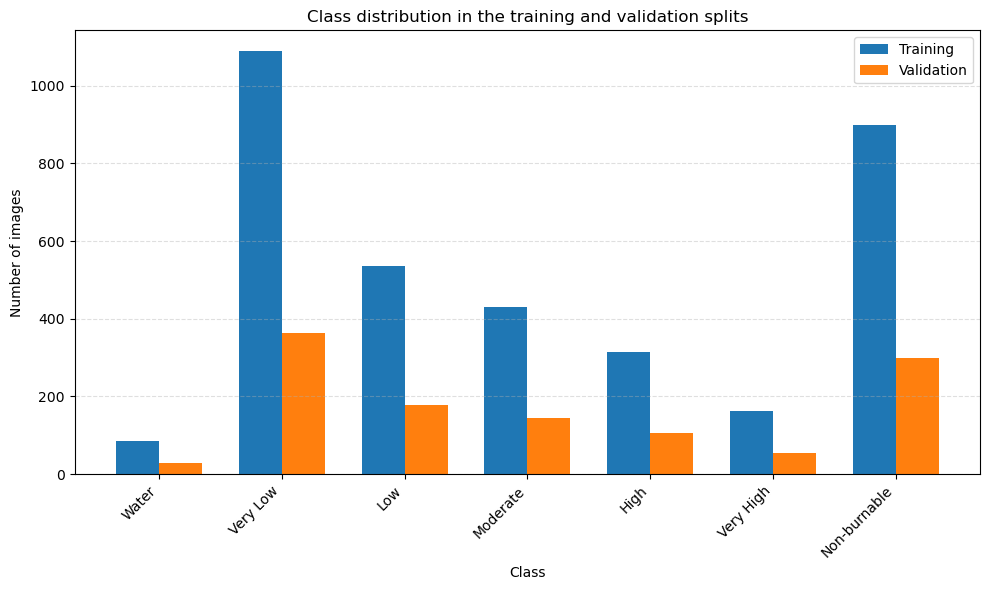

Training: 3516, validation: 1172, test: 1173


In [30]:
# Count labelled images. Test labels are hidden, so no test class histogram is shown.

df_train = pd.read_csv(DB_DIR / 'train_reduced.csv', dtype={'id': str, 'label': int})
df_val = pd.read_csv(DB_DIR / 'val_reduced.csv', dtype={'id': str, 'label': int})
df_test = pd.read_csv(DB_DIR / 'test_reduced.csv', dtype={'id': str, 'label': int})

all_labels = np.arange(NUM_CLASSES)

train_counts = df_train['label'].value_counts().reindex(all_labels, fill_value=0)
val_counts = df_val['label'].value_counts().reindex(all_labels, fill_value=0)

for split_name, frame in [('training', df_train), ('validation', df_val)]:
    if frame.empty or not frame['label'].isin(all_labels).all():
        raise ValueError(f'The {split_name} split must have labels 0 through 6.')

if df_test.empty or not (df_test['label'] == -1).all():
    raise ValueError('The test split must be nonempty and have hidden labels (-1).')

if any(frame['id'].duplicated().any() for frame in (df_train, df_val, df_test)):
    raise ValueError('An index file contains duplicate image IDs.')

if (set(df_train['id']) & set(df_val['id']) or
    set(df_train['id']) & set(df_test['id']) or
    set(df_val['id']) & set(df_test['id'])):
    raise ValueError('Training, validation and test image IDs must be disjoint.')

x = np.arange(NUM_CLASSES)
width = 0.35
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width / 2, train_counts.to_numpy(), width, label='Training')
ax.bar(x + width / 2, val_counts.to_numpy(), width, label='Validation')
ax.set_xlabel('Class')
ax.set_ylabel('Number of images')
ax.set_title('Class distribution in the training and validation splits')
ax.set_xticks(x, CLASS_NAMES, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)
fig.tight_layout()
plt.show()
print(f'Training: {len(df_train)}, validation: {len(df_val)}, test: {len(df_test)}')

### Preparing the dataset


Read the training index file and inspect example 100. Each row identifies an image and its class index:

`0 = Water`, `1 = Very Low`, `2 = Low`, `3 = Moderate`, `4 = High`, `5 = Very High`, `6 = Non-burnable`.


In [31]:
db = pd.read_csv(DB_DIR / 'train_reduced.csv', dtype={'id': str, 'label': int})

n = min(100, len(db) - 1)
img_id = db.iloc[n]['id']
label = int(db.iloc[n]['label'])

print(f'Image ID: {img_id}')
print(f'Label: {label} ({CLASS_NAMES[label]})')

Image ID: 34574541
Label: 1 (Very Low)


Define a small helper to display an image and its title.


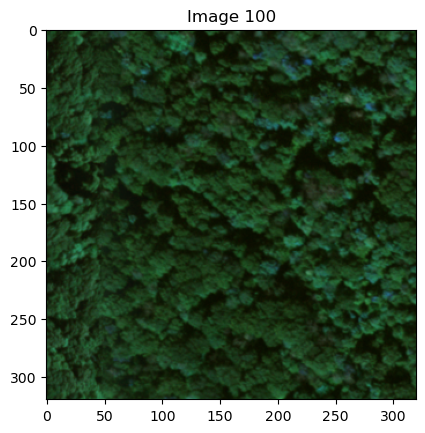

In [32]:
def imshow(image, title_str):
    plt.imshow(image, cmap='gray' if image.ndim == 2 else None)
    plt.title(title_str)

plt.figure()
imshow(io.imread(DB_DIR / 'images' / f'{img_id}.jpg'), f'Image {n}')
plt.show()

### The Dataset class

`torch.utils.data.Dataset` is the abstract interface for a PyTorch dataset. Implement a subclass with:

- `__init__`: read the index and store configuration.
- `__len__`: return the number of samples.
- `__getitem__`: read and return a sample by index.

Read image files in `__getitem__`, rather than loading the entire image collection at construction time. This limits memory use.

Each sample is a dictionary: `{'image': image, 'label': label}`. The optional `transform` argument applies preprocessing and augmentation when a sample is requested. The class-name list is ordered by the numeric labels, so plot labels and output columns remain consistent.


In [33]:
class FireRiskDataset(Dataset):
    """Read RGB images and integer labels using a CSV index.

    Args:
        csv_file: CSV with columns 'id' and 'label'.
        root_dir: Dataset directory containing the 'images' subdirectory.
        transform: Optional callable that receives and returns a sample dictionary.
        maxSize: Maximum subset size; 0 selects the full split.
    """

    def __init__(self, csv_file, root_dir, transform=None, maxSize=0):

        if not isinstance(maxSize, numbers.Integral) or maxSize < 0:
            raise ValueError('maxSize must be a nonnegative integer.')

        self.dataset = pd.read_csv(csv_file, dtype={'id': str, 'label': int})

        if not {'id', 'label'}.issubset(self.dataset.columns) or self.dataset.empty:
            raise ValueError('The CSV must contain nonempty id and label columns.')
        if not self.dataset['label'].isin(range(-1, NUM_CLASSES)).all():
            raise ValueError('Labels must be -1 (hidden test labels) or 0 through 6.')
        if maxSize > 0:
            indices = np.random.RandomState(SEED).permutation(len(self.dataset))
            self.dataset = self.dataset.iloc[indices[:maxSize]].reset_index(drop=True)

        self.img_dir = Path(root_dir) / 'images'
        self.transform = transform
        self.classes = CLASS_NAMES.copy()

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):

        if torch.is_tensor(idx):
            idx = idx.item()
        row = self.dataset.iloc[int(idx)]
        image = util.img_as_float32(io.imread(self.img_dir / f"{row['id']}.jpg"))

        if image.ndim == 2:
            image = np.repeat(image[..., None], 3, axis=2)
        elif image.ndim == 3 and image.shape[2] == 4:
            image = image[..., :3]
        if image.ndim != 3 or image.shape[2] != 3:
            raise ValueError('Expected an RGB image with three channels.')
        sample = {'image': image, 'label': int(row['label'])}

        return self.transform(sample) if self.transform is not None else sample

Instantiate the dataset and display a few samples.


0 (320, 320, 3) 0
1 (320, 320, 3) 0
2 (320, 320, 3) 0
3 (320, 320, 3) 0


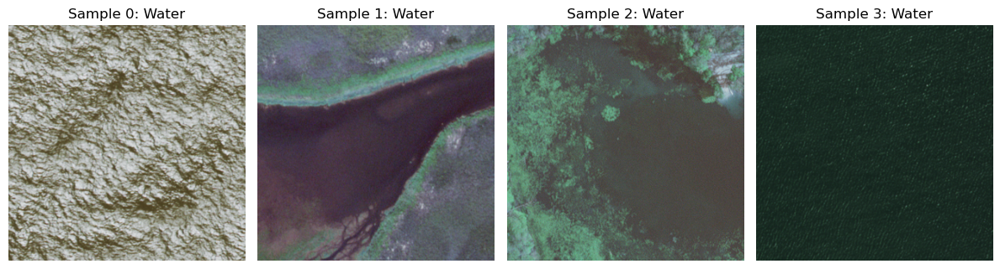

In [34]:
train_dataset = FireRiskDataset(DB_DIR / 'train_reduced.csv', DB_DIR)
fig, axes = plt.subplots(1, 4, figsize=(12, 4))

for i, ax in enumerate(axes):
    ax.axis('off')
    if i >= len(train_dataset):
        continue
    sample = train_dataset[i]
    print(i, sample['image'].shape, sample['label'])
    ax.set_title(f"Sample {i}: {CLASS_NAMES[sample['label']]}")
    ax.imshow(sample['image'])

fig.tight_layout()
plt.show()

**IMPORTANT:** `maxSize` optionally limits the number of images by selecting a reproducible random subset. Set `maxSize=0` to use the full split.

Small subsets are useful for checking code and exploring hyperparameters quickly. Conclusions obtained from a subset may differ from those obtained with the full training split. Use the full training split for your final model.


### Preprocessing and data augmentation

Augmentation creates random variations of training images and can *improve* generalisation and thus *reduce* potential overfitting. Apply random augmentation to **training** data; validation and test preprocessing should be deterministic.

We implement five callable transforms:

- `Rescale`: resize to a specified shape, or resize the shorter side while preserving aspect ratio.
- `RandomCrop`: select a random image patch, used during training.
- `CenterCrop`: take the central patch, used for validation and test.
- `ToTensor`: convert a NumPy image from `H x W x C` to a float32 PyTorch tensor in `C x H x W` order.
- `Normalize`: subtract the RGB channel means and divide by the channel standard deviations.

Callable classes store transform parameters in `__init__` and apply the operation in `__call__`:

```python
tsfm = Transform(parameters)
transformed_sample = tsfm(sample)
```

Crops must fit the input image. Resize first if you want to crop an image that is smaller than the requested crop.


In [35]:
def _crop_size(output_size):

    if isinstance(output_size, numbers.Integral):
        output_size = (int(output_size), int(output_size))

    if (not isinstance(output_size, tuple) or len(output_size) != 2 or
        any(not isinstance(v, numbers.Integral) or v <= 0 for v in output_size)):
        raise ValueError('Size must be a positive integer or a pair of positive integers.')

    return tuple(int(v) for v in output_size)

class Rescale:
    """Resize to (height, width), or resize the shorter side preserving aspect ratio."""

    def __init__(self, output_size):
        self.output_size = (int(output_size) if isinstance(output_size, numbers.Integral)
                            else _crop_size(output_size))
        if isinstance(self.output_size, int) and self.output_size <= 0:
            raise ValueError('The output size must be positive.')

    def __call__(self, sample):
        image, label = sample['image'], sample['label']
        h, w = image.shape[:2]
        if isinstance(self.output_size, int):
            scale = self.output_size / min(h, w)
            new_h, new_w = round(h * scale), round(w * scale)
        else:
            new_h, new_w = self.output_size
        image = transform.resize(image, (new_h, new_w), anti_aliasing=True)

        return {'image': image.astype(np.float32), 'label': label}

class RandomCrop:
    """Choose uniformly among all valid crops, including the final row/column."""

    def __init__(self, output_size):
        self.output_size = _crop_size(output_size)

    def __call__(self, sample):

        image, label = sample['image'], sample['label']
        h, w = image.shape[:2]
        new_h, new_w = self.output_size

        if new_h > h or new_w > w:
            raise ValueError('Crop exceeds image dimensions; resize the image first.')
        top = np.random.randint(0, h - new_h + 1)
        left = np.random.randint(0, w - new_w + 1)

        return {'image': image[top:top + new_h, left:left + new_w], 'label': label}

class CenterCrop:
    """Take a deterministic central crop without silently changing its size."""

    def __init__(self, output_size):
        self.output_size = _crop_size(output_size)

    def __call__(self, sample):

        image, label = sample['image'], sample['label']
        h, w = image.shape[:2]
        new_h, new_w = self.output_size

        if new_h > h or new_w > w:
            raise ValueError('Crop exceeds image dimensions; resize the image first.')
        top, left = (h - new_h) // 2, (w - new_w) // 2

        return {'image': image[top:top + new_h, left:left + new_w], 'label': label}

class ToTensor:
    """Convert HWC images to contiguous float32 CHW tensors and labels to int64."""

    def __call__(self, sample):
        image = np.ascontiguousarray(sample['image'].transpose(2, 0, 1), dtype=np.float32)
        return {'image': torch.from_numpy(image),
                'label': torch.tensor(sample['label'], dtype=torch.long)}

class Normalize:
    """Apply per-channel normalisation without mutating the input tensor."""

    def __init__(self, mean, std):

        self.mean = np.asarray(mean, dtype=np.float32)
        self.std = np.asarray(std, dtype=np.float32)

        if (self.mean.ndim != 1 or self.std.shape != self.mean.shape or
            not np.isfinite(self.mean).all() or not np.isfinite(self.std).all() or
            not (self.std > 0).all()):
            raise ValueError('Mean/std must be matching finite vectors with positive std.')

    def __call__(self, sample):

        image = sample['image']

        if image.ndim != 3 or image.shape[0] != len(self.mean):
            raise ValueError('The CHW tensor and normalisation vectors must match.')

        mean = torch.as_tensor(self.mean, dtype=image.dtype, device=image.device)[:, None, None]
        std = torch.as_tensor(self.std, dtype=image.dtype, device=image.device)[:, None, None]
        return {'image': (image - mean) / std, 'label': sample['label']}

#### Exercise

Use the following cell to apply transforms. Experiment with their parameters and read each class's docstring to understand its behaviour.


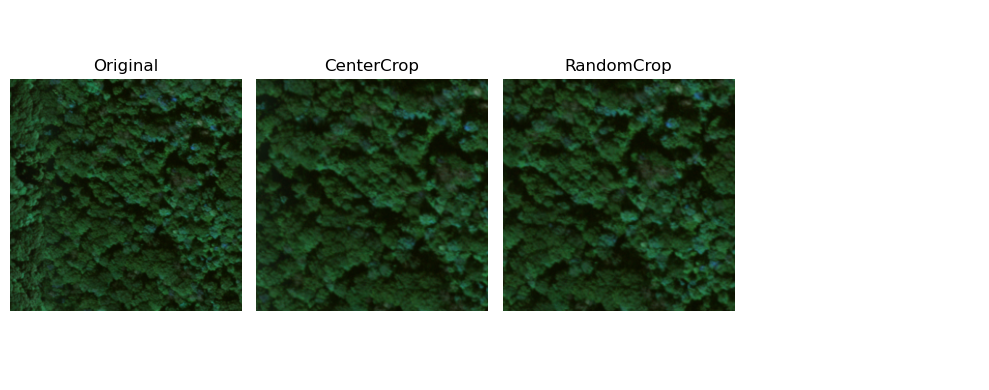

torch.Size([3, 320, 320])
torch.float32
tensor(2)


In [36]:
# Modify the transform parameters to explore their effects.
sample = train_dataset[min(100, len(train_dataset) - 1)]

fig, axes = plt.subplots(1, 4, figsize=(10, 4))
axes[0].imshow(sample['image'])
axes[0].set_title('Original')

for ax, tsfrm in zip(axes[1:], [CenterCrop(224), RandomCrop(224)]):
    ax.imshow(tsfrm(sample)['image'])
    ax.set_title(type(tsfrm).__name__)
for ax in axes:
    ax.axis('off')

fig.tight_layout()

plt.show()

to_tensor = ToTensor()

sample = {
    'image': np.random.rand(320, 320, 3).astype(np.float32),
    'label': 2
}

converted = to_tensor(sample)

print(converted['image'].shape)  # torch.Size([3, 320, 320])
print(converted['image'].dtype)  # torch.float32
print(converted['label'])        # tensor(2)

### The torchvision.transforms package

`torchvision.transforms` supplies many useful image transforms. Depending on the transform, inputs can be PIL images or PyTorch tensors. Our dataset initially returns NumPy images, so a wrapper may need to:

1. Convert the NumPy image to a PIL image.
2. Apply a torchvision transform.
3. Convert back to a NumPy image while preserving the label.

The `TVCenterCrop` class below demonstrates this pattern. This is an image-classification task: there is no segmentation mask to transform. When adapting this pattern to segmentation, image and mask geometry would need to remain aligned.


In [37]:
class TVCenterCrop:
    """Wrap torchvision CenterCrop for a NumPy image/sample dictionary."""

    def __init__(self, size):
        self.size = _crop_size(size)
        self.crop = transforms.CenterCrop(self.size)

    def __call__(self, sample):

        image = sample['image']

        if any(crop > actual for crop, actual in zip(self.size, image.shape[:2])):
            raise ValueError('Crop exceeds image dimensions; resize the image first.')

        pil_image = Image.fromarray(util.img_as_ubyte(image))
        image = util.img_as_float32(np.asarray(self.crop(pil_image)))
        return {'image': image, 'label': sample['label']}

Apply the wrapper to inspect its output.


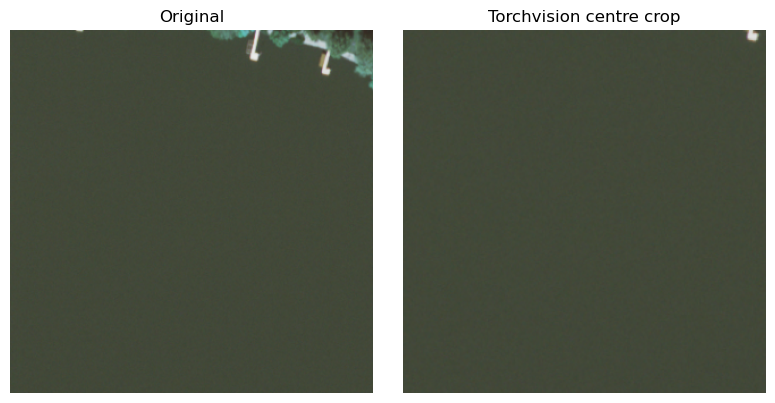

In [38]:
sample = train_dataset[min(65, len(train_dataset) - 1)]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sample['image'])
axes[0].set_title('Original')
axes[1].imshow(TVCenterCrop(256)(sample)['image'])
axes[1].set_title('Torchvision centre crop')

for ax in axes:
    ax.axis('off')

fig.tight_layout()

plt.show()

#### Exercise

Implement other transforms that could help with this dataset, using `scikit-image` or `torchvision.transforms` as appropriate.


In [39]:
class ApplyToImage:
    """Apply an image-only transform while preserving the sample's other fields.

    For the tensor transforms below, use this wrapper after ToTensor() and
    before Normalize(). ColorJitter expects the image to still be in [0, 1].
    """

    def __init__(self, transform):
        self.transform = transform

    def __call__(self, sample):
        return {**sample, 'image': self.transform(sample['image'])}


class RandomRotate90:
    """Rotate a CHW tensor by a uniformly sampled 0, 90, 180 or 270 degrees.

    No interpolation or corner padding is needed. Use square inputs to keep
    the same height and width for batching.
    """

    def __call__(self, image):
        k = torch.randint(0, 4, ()).item()
        return torch.rot90(image, k, dims=(-2, -1)).contiguous()


### Comparing transform compositions

Compare all 32 on/off combinations of five augmentations, including a baseline,
on one training image from each class. Every pipeline produces a normalised
`3 x 224 x 224` tensor. C changes the spatial strategy from full-image resizing
to a random 224-pixel crop; H/V/R/J add flips, right-angle rotations and mild
colour jitter. Enabled random operations can still choose the identity.

Then compare all 24 orders of H/V/R/J with fixed parameters. Tensor conversion
always precedes these tensor operations and normalisation is always last.
Invalid permutations (such as normalising before tensor conversion) are excluded.
These plots test output appearance and correctness, not predictive performance.


#### Exercise

Try different transform compositions and parameters. Examine how changing the order of operations affects the output.


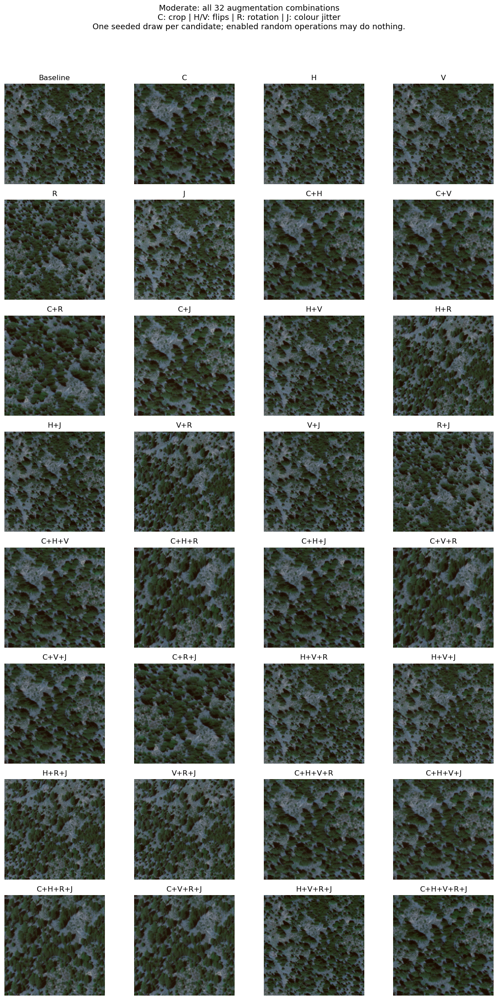

Checked 224 outputs: 32 combinations x 7 classes.
All outputs are finite float32 tensors with shape (3, 224, 224); labels preserved.
All seven class galleries and checks saved to: /Users/collin/Documents/Computer Vision/CodaBench/[Public] Lab 4 AVCV 2026 2027/outputs/Lab_4_2026_2027/augmentation_comparison


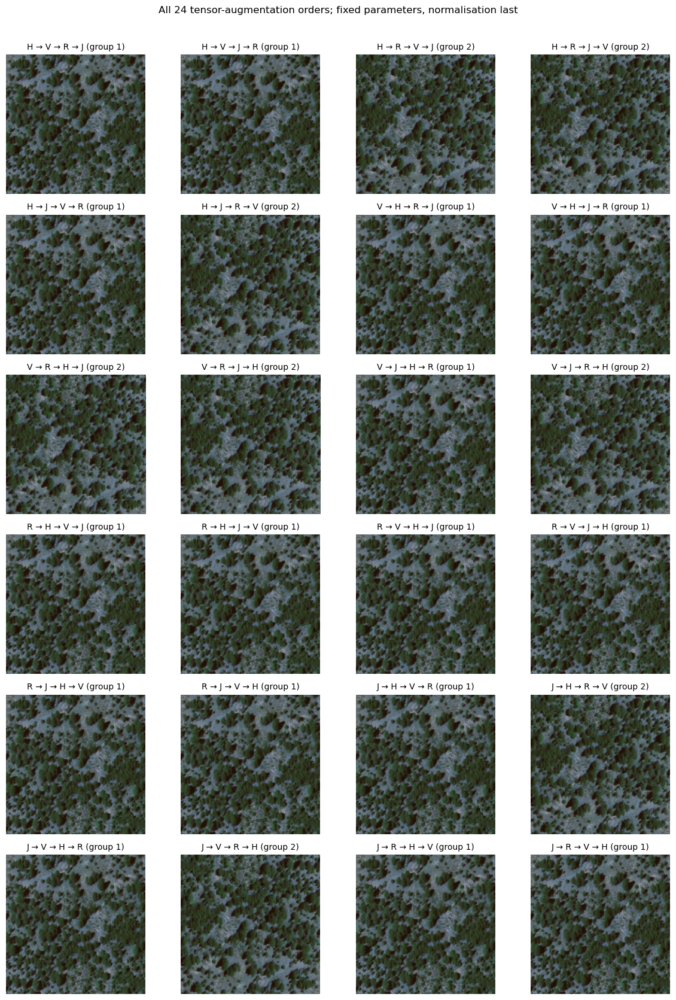

24 orders produced 2 distinct outputs within numerical tolerance.
Visual differences and pixel statistics do not measure validation accuracy.


In [40]:
from itertools import combinations, permutations


def image_for_display(tensor):
    """Undo normalisation for display; these RGB pixels are not model inputs."""
    image = tensor.detach().cpu()
    mean = torch.tensor(PIXEL_MEAN, dtype=image.dtype)[:, None, None]
    std = torch.tensor(PIXEL_STD, dtype=image.dtype)[:, None, None]
    return (image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


def make_augmentation_pipeline(enabled):
    """Build a training candidate, keeping preprocessing order valid.

    C=crop, H=horizontal flip, V=vertical flip, R=right-angle rotation,
    J=mild colour jitter. Without C, resize the whole scene to 224 x 224.
    """
    operations = {
        'H': transforms.RandomHorizontalFlip(p=0.5),
        'V': transforms.RandomVerticalFlip(p=0.5),
        'R': RandomRotate90(),
        'J': transforms.ColorJitter(
            brightness=0.1, contrast=0.1, saturation=0.05,
        ),
    }
    return transforms.Compose([
        RandomCrop(224) if 'C' in enabled else Rescale((224, 224)),
        ToTensor(),
        ApplyToImage(transforms.Compose([
            operations[key] for key in ('H', 'V', 'R', 'J') if key in enabled
        ])),
        Normalize(PIXEL_MEAN, PIXEL_STD),
    ])


# All 2**5 subsets, including the baseline with no random augmentation.
augmentation_combinations = [
    subset for size in range(6) for subset in combinations('CHVRJ', size)
]
augmentation_candidates = {
    '+'.join(subset) or 'Baseline': make_augmentation_pipeline(subset)
    for subset in augmentation_combinations
}

comparison_dataset = FireRiskDataset(DB_DIR / 'train_reduced.csv', DB_DIR)
# Use one actual training image per class to check varied land-cover types.
comparison_indices = [
    int(comparison_dataset.dataset.index[
        comparison_dataset.dataset['label'] == label
    ][0]) for label in range(NUM_CLASSES)
]
comparison_dir = OUTPUT_DIR / 'augmentation_comparison'
comparison_dir.mkdir(parents=True, exist_ok=True)
comparison_rows = []

# Preserve RNG state so running this visual experiment does not change training.
numpy_rng_state = np.random.get_state()
try:
    with torch.random.fork_rng(devices=[]):
        for index in comparison_indices:
            original = comparison_dataset[index]
            label = original['label']
            fig, axes = plt.subplots(8, 4, figsize=(12, 23))
            for ax, (name, pipeline) in zip(axes.flat, augmentation_candidates.items()):
                np.random.seed(SEED)
                torch.random.default_generator.manual_seed(SEED)
                result = pipeline(original)
                image = result['image']
                assert image.shape == (3, 224, 224)
                assert image.dtype == torch.float32 and torch.isfinite(image).all()
                assert int(result['label']) == label
                rgb = image_for_display(image)
                ax.imshow(rgb)
                ax.set_title(name)
                ax.axis('off')
                comparison_rows.append({
                    'class': CLASS_NAMES[label], 'combination': name,
                    'shape': str(tuple(image.shape)),
                    'tensor_min': float(image.min()),
                    'tensor_max': float(image.max()),
                    'display_mean_r': float(rgb[..., 0].mean()),
                    'display_mean_g': float(rgb[..., 1].mean()),
                    'display_mean_b': float(rgb[..., 2].mean()),
                    'label_preserved': int(result['label']) == label,
                })
            fig.suptitle(
                f"{CLASS_NAMES[label]}: all 32 augmentation combinations\n"
                'C: crop | H/V: flips | R: rotation | J: colour jitter\n'
                'One seeded draw per candidate; enabled random operations may do nothing.',
                fontsize=13,
            )
            fig.tight_layout(rect=(0, 0, 1, 0.95))
            fig.savefig(comparison_dir / f'class_{label}_combinations.png', dpi=110)
            # Display one representative gallery; save the others for inspection.
            if label == 3:
                plt.show()
            plt.close(fig)
finally:
    np.random.set_state(numpy_rng_state)

comparison_results = pd.DataFrame(comparison_rows)
comparison_results.to_csv(comparison_dir / 'combination_checks.csv', index=False)
print(f'Checked {len(comparison_results)} outputs: 32 combinations x {NUM_CLASSES} classes.')
print('All outputs are finite float32 tensors with shape (3, 224, 224); labels preserved.')
print(f'All seven class galleries and checks saved to: {comparison_dir.resolve()}')

# Compare all 4! orders of the tensor augmentations under CONTROLLED parameters.
# Force both flips and a 90-degree rotation; replay the SAME jitter RNG for each
# ordering. This isolates operation order from different random parameter draws.
order_operations = {
    'H': transforms.RandomHorizontalFlip(p=1.0),
    'V': transforms.RandomVerticalFlip(p=1.0),
    'R': lambda image: torch.rot90(image, 1, (-2, -1)),
    'J': transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.05),
}
order_sample = comparison_dataset[comparison_indices[3]]
order_input = ToTensor()(Rescale((224, 224))(order_sample))
order_outputs = []
order_rows = []
fig, axes = plt.subplots(6, 4, figsize=(12, 17))
for ax, order in zip(axes.flat, permutations('HVRJ')):
    result = order_input
    for key in order:
        # Each operation gets the same parameters wherever it appears.
        with torch.random.fork_rng(devices=[]):
            torch.random.default_generator.manual_seed(SEED)
            result = ApplyToImage(order_operations[key])(result)
    result = Normalize(PIXEL_MEAN, PIXEL_STD)(result)
    output = result['image']
    assert output.shape == (3, 224, 224) and torch.isfinite(output).all()
    # Group numerically equivalent images; this is NOT an accuracy ranking.
    match = next((i for i, previous in enumerate(order_outputs)
                  if torch.allclose(output, previous, atol=1e-5, rtol=1e-5)), None)
    if match is None:
        match = len(order_outputs)
        order_outputs.append(output)
    name = ' → '.join(order)
    order_rows.append({'order': name, 'equivalent_output_group': match + 1})
    ax.imshow(image_for_display(output))
    ax.set_title(f'{name} (group {match + 1})', fontsize=10)
    ax.axis('off')
fig.suptitle('All 24 tensor-augmentation orders; fixed parameters, normalisation last')
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(comparison_dir / 'operation_orders.png', dpi=110)
plt.show()
plt.close(fig)
order_results = pd.DataFrame(order_rows)
order_results.to_csv(comparison_dir / 'order_checks.csv', index=False)
print(f'24 orders produced {len(order_outputs)} distinct outputs within numerical tolerance.')
print('Visual differences and pixel statistics do not measure validation accuracy.')


### Interpreting the comparison

Start by comparing **H+V+R** against **H+V+R+J**, using full-image resizing.
This is a hypothesis, not a measured winner: orientation changes preserve the
scene's land-cover content, while mild jitter may help with lighting differences.
Crops can be useful but remove context and may change the visible proportions of
water, vegetation or built areas relative to the image-level label.

H+V+R contains some redundancy: uniform right-angle rotations plus either one
random flip already cover the eight symmetries of a square. Changing operation
order can yield the same image or another orientation; more permutations do not
necessarily create more useful diversity. Colour jitter should stay before
normalisation, and stronger colour changes may obscure vegetation cues.

To choose the best candidate, train a fresh copy of the same model for each
configuration with the same initial weights, split, batch order, optimiser and
epoch budget. Use a fixed validation transform for every run; compare validation
accuracy and per-class recall over several seeds. Do not select on test labels.
The custom CNN below is implemented, but this visual comparison does not
train it or claim an accuracy winner. The existing training selection below
is retained until validation evidence supports changing it.

To try a candidate later, set `train_transform = augmentation_candidates['H+V+R']`
(or another gallery title) immediately before creating the training dataset.


#### Satellite-image augmentation

The pipeline below adds horizontal and vertical flips, rotations by multiples of
90 degrees, and mild colour jitter. These are candidate augmentations: compare
validation performance with the original crop-only baseline to see whether they
help. Small colour changes preserve more of the vegetation and land-cover cues
than strong hue changes or grayscale conversion.

Order: NumPy crop → tensor conversion → flips/rotations → colour jitter →
normalisation. `ApplyToImage` lets torchvision transforms operate on the image
inside our sample dictionary. The label is preserved. Right-angle rotations
avoid padded corners; square crops keep batch shapes consistent.

The preview shows fresh random variants of the same training image. Random
augmentation is used only for training; validation and test retain their
existing deterministic preprocessing.


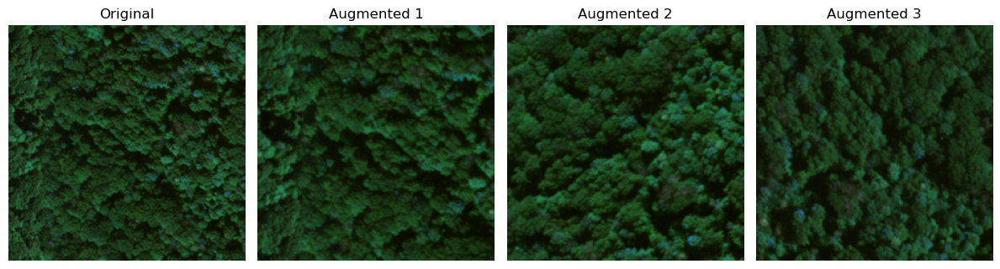

In [41]:
train_transform = transforms.Compose([
    RandomCrop(224),
    ToTensor(),
    ApplyToImage(transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        RandomRotate90(),
        transforms.ColorJitter(
            brightness=0.1, contrast=0.1, saturation=0.05,
        ),
    ])),
    Normalize(PIXEL_MEAN, PIXEL_STD),
])

# Load an untransformed sample so this preview can also be rerun after training
# datasets have been constructed.
preview_dataset = FireRiskDataset(DB_DIR / 'train_reduced.csv', DB_DIR)
preview_sample = preview_dataset[min(100, len(preview_dataset) - 1)]
fig, axes = plt.subplots(1, 4, figsize=(12, 4))
axes[0].imshow(preview_sample['image'])
axes[0].set_title('Original')
for i, ax in enumerate(axes[1:], start=1):
    augmented_sample = train_transform(preview_sample)
    ax.imshow(image_for_display(augmented_sample['image']))
    ax.set_title(f'Augmented {i}')
for ax in axes:
    ax.axis('off')
fig.tight_layout()
plt.show()


### Iterating over the dataset

Combine image loading and transforms to create the training, validation and test datasets.

For each training sample, the dataset reads the image and applies `train_transform`,
which samples a crop, flips, a right-angle rotation and mild colour changes before
normalisation. Validation and test use a deterministic central crop.


In [42]:
train_dataset = FireRiskDataset(
    DB_DIR / 'train_reduced.csv', DB_DIR, maxSize=MAX_TRAIN_SAMPLES,
    transform=train_transform)

val_dataset = FireRiskDataset(
    DB_DIR / 'val_reduced.csv', DB_DIR,
    transform=transforms.Compose([
        CenterCrop(224), ToTensor(), Normalize(PIXEL_MEAN, PIXEL_STD),
    ]))

test_dataset = FireRiskDataset(
    DB_DIR / 'test_reduced.csv', DB_DIR,
    transform=transforms.Compose([
        CenterCrop(224), ToTensor(), Normalize(PIXEL_MEAN, PIXEL_STD),
    ]))

for i in range(min(4, len(train_dataset))):
    sample = train_dataset[i]
    print(i, sample['image'].shape, int(sample['label']))

print(f'Training subset size: {len(train_dataset)}')

0 torch.Size([3, 224, 224]) 5
1 torch.Size([3, 224, 224]) 0
2 torch.Size([3, 224, 224]) 1
3 torch.Size([3, 224, 224]) 1
Training subset size: 500


Finally, create DataLoaders to group samples into batches and shuffle training examples.

`torch.utils.data.DataLoader` is an iterable that can also load data using worker processes. `num_workers=0` is the portable notebook default here: notebook-defined dataset classes can cause multiprocessing problems on platforms that use process spawning. Increase the worker count only after verifying that your environment supports it.

The default `collate_fn` stacks the tensors in our sample dictionaries. Keep validation and test loaders unshuffled; submission rows must follow the test CSV order.


0 torch.Size([64, 3, 224, 224]) tensor([0, 1, 1, 1, 6, 2, 4, 2, 6, 3, 1, 2, 3, 2, 6, 6, 4, 3, 2, 4, 2, 3, 1, 4,
        6, 6, 4, 1, 6, 1, 6, 1, 0, 1, 6, 6, 3, 1, 2, 3, 2, 1, 1, 2, 2, 5, 4, 6,
        3, 6, 5, 2, 4, 6, 1, 1, 5, 1, 3, 1, 6, 1, 2, 1])


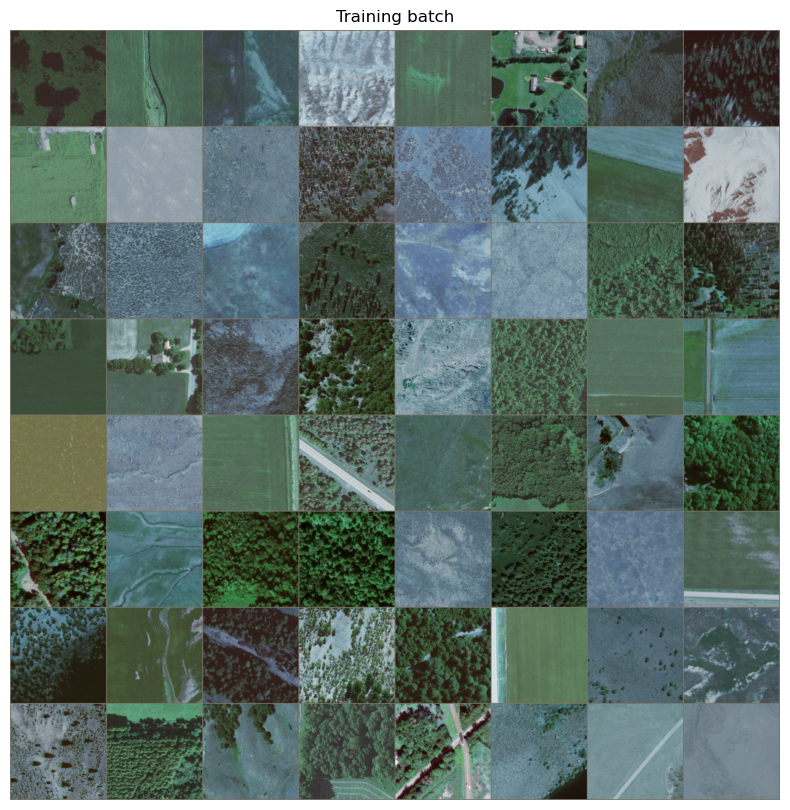

1 torch.Size([64, 3, 224, 224]) tensor([1, 6, 3, 2, 6, 6, 4, 4, 6, 1, 2, 1, 6, 1, 1, 1, 6, 3, 1, 2, 6, 1, 6, 3,
        1, 1, 2, 3, 1, 3, 6, 1, 1, 3, 1, 6, 1, 6, 2, 1, 2, 1, 2, 1, 5, 1, 2, 3,
        3, 6, 1, 6, 1, 2, 2, 1, 2, 5, 1, 6, 6, 6, 4, 2])


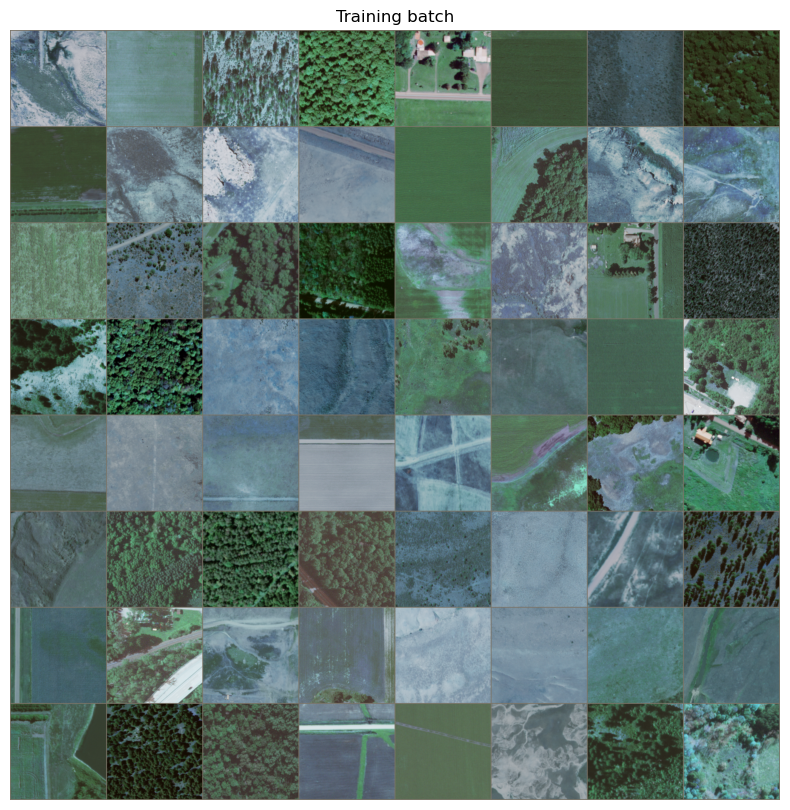

2 torch.Size([64, 3, 224, 224]) tensor([1, 1, 4, 1, 1, 4, 3, 1, 2, 6, 1, 2, 1, 6, 3, 6, 3, 1, 1, 6, 1, 1, 6, 6,
        1, 2, 4, 6, 6, 6, 6, 3, 2, 3, 6, 4, 3, 6, 1, 3, 3, 6, 6, 6, 6, 6, 6, 1,
        6, 6, 1, 1, 1, 1, 2, 1, 2, 1, 2, 6, 1, 5, 5, 1])


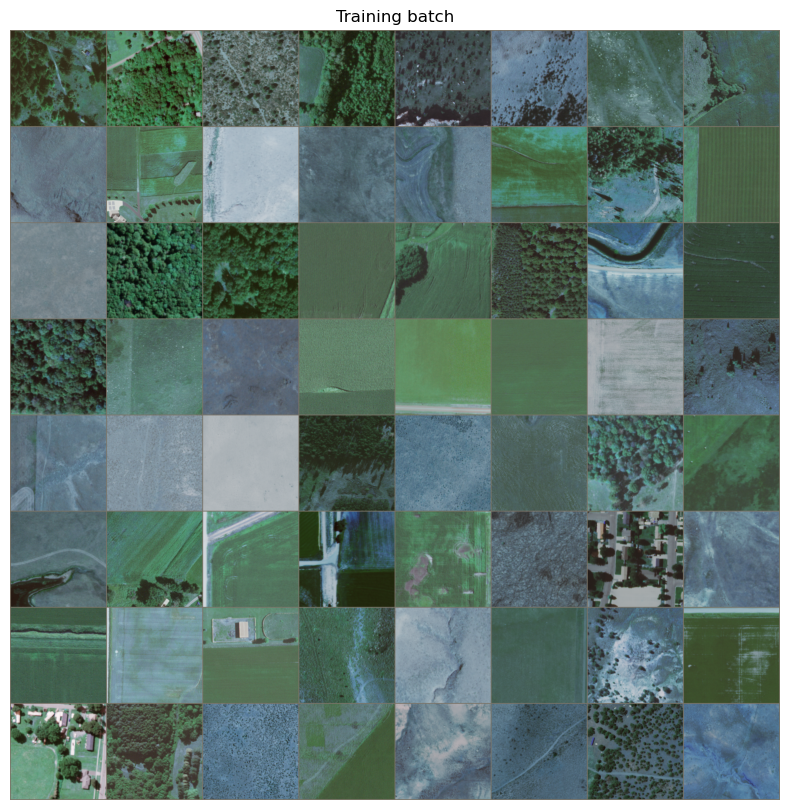

3 torch.Size([64, 3, 224, 224]) tensor([1, 6, 1, 2, 1, 1, 0, 6, 1, 1, 4, 1, 0, 4, 1, 1, 1, 6, 1, 1, 4, 1, 6, 2,
        4, 1, 0, 6, 1, 3, 1, 0, 1, 2, 2, 1, 4, 1, 3, 4, 1, 6, 5, 6, 1, 6, 1, 6,
        2, 1, 2, 5, 1, 4, 1, 2, 1, 5, 4, 1, 5, 3, 0, 2])


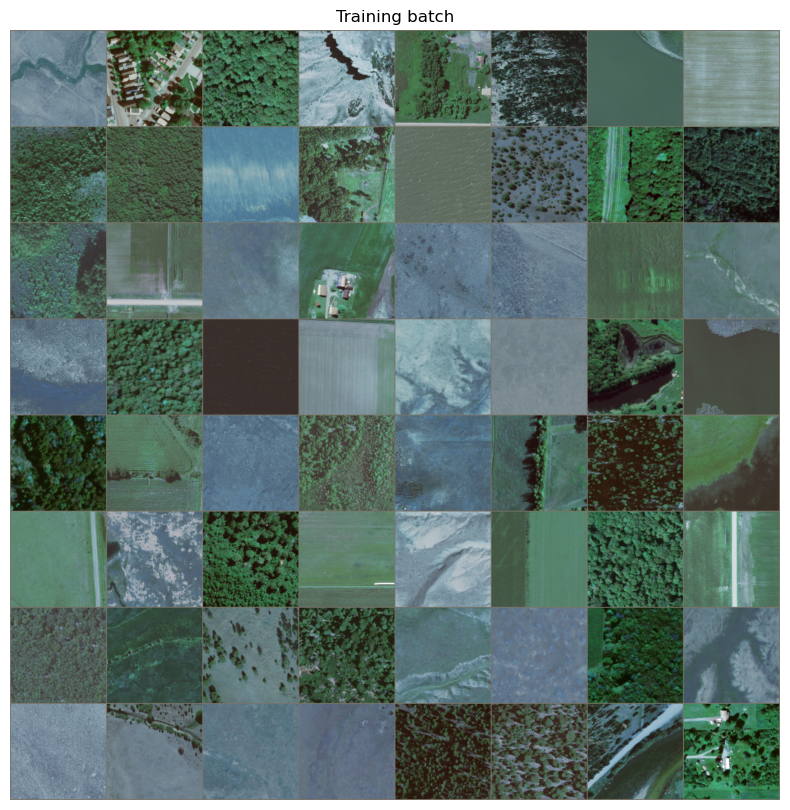

In [43]:
def seed_worker(worker_id):
    # PyTorch assigns a worker seed; also seed NumPy and Python random.
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

train_generator = torch.Generator().manual_seed(SEED)
train_dataloader = DataLoader(
    train_dataset, batch_size=64, shuffle=True, num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker, generator=train_generator)
val_dataloader = DataLoader(
    val_dataset, batch_size=128, shuffle=False, num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker)
test_dataloader = DataLoader(
    test_dataset, batch_size=128, shuffle=False, num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker)

def show_batch(sample_batched):
    grid = utils.make_grid(sample_batched['image'])
    plt.imshow(image_for_display(grid))
    plt.title('Training batch')
    plt.axis('off')

for i_batch, sample_batched in enumerate(train_dataloader):
    print(i_batch, sample_batched['image'].shape, sample_batched['label'])
    plt.figure(figsize=(10, 10))
    show_batch(sample_batched)
    plt.show()
    if i_batch == 3:
        break

## Part 2: Building a custom fire-risk network

In this second part of the notebook we will be focused on building a CNN from scratch. Its architecture must match the input image size; this reference pipeline uses 224 x 224 crops.

The next cell defines `CustomNet`, with `__init__` to create layers and `forward` to connect them. The network must map a batch of shape `N x 3 x 224 x 224` to seven logits per image, shape `N x 7`. Pass raw logits to cross-entropy; apply softmax *only* when obtaining probabilities for reporting or submission.

In [44]:
class CustomNet(nn.Module):
    """CNN trained from scratch: N x 3 x 224 x 224 -> N x 7 raw logits."""

    def __init__(self):
        super().__init__()
        # Each block applies a 5x5 convolution, ReLU and 2x2 max pooling.
        self.conv1 = nn.Conv2d(3, 6, kernel_size=5)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.conv3 = nn.Conv2d(16, 32, kernel_size=5)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Spatial sizes: 224 -> 110 -> 53 -> 24 after the three blocks.
        self.fc1 = nn.Linear(32 * 24 * 24, 120)
        self.fc2 = nn.Linear(120, NUM_CLASSES)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # N x 6 x 110 x 110
        x = self.pool(F.relu(self.conv2(x)))  # N x 16 x 53 x 53
        x = self.pool(F.relu(self.conv3(x)))  # N x 32 x 24 x 24
        x = x.flatten(1)                     # N x 18432
        x = F.relu(self.fc1(x))              # N x 120
        return self.fc2(x)                  # N x 7; CrossEntropyLoss needs logits


#### Exercise

Define or modify a network that accepts batches of RGB images and produces seven class scores per image.

**IMPORTANT:** Match layer dimensions. With three 5 x 5 convolutions of stride 1 and a 2 x 2 pooling layer after each convolution, the spatial sizes for a 224 x 224 input are:

`224 → 220 → 110 → 106 → 53 → 49 → 24`.

For 32 channels after the third block, flattening produces `32 x 24 x 24` features. If you change the architecture or input size, update the fully connected layer accordingly. The following cell checks the output shape.


#### Tip

Inspect shapes one block at a time. Temporarily return the output of the first convolution/pooling block, run the next cell and check its dimensions. Extend the forward pass progressively until the final output is `N x 7`.


In [45]:
seed_everything()

customNet = CustomNet().to(device)

data = next(iter(train_dataloader))
inputs = data['image'].to(device, dtype=torch.float32)

print(f'Input batch shape: {tuple(inputs.shape)}')

with torch.no_grad():
    outputs = customNet(inputs)
if outputs.shape != (inputs.shape[0], NUM_CLASSES):
    raise ValueError('CustomNet must produce one seven-score vector per image.')

print(f'Output batch shape: {tuple(outputs.shape)}')

Input batch shape: (64, 3, 224, 224)
Output batch shape: (64, 7)


## Part 3: Training the network

We now define the evaluation metric, loss, optimiser and learning-rate schedule.

### Evaluation metric: macro F1

For a class, precision is the fraction of predicted positives that are correct, and recall is the fraction of actual positives correctly identified:

$$\operatorname{precision}=\frac{TP}{TP+FP},\qquad
\operatorname{recall}=\frac{TP}{TP+FN}.$$

F1 is their harmonic mean:

$$F_1=\frac{2\,\operatorname{precision}\,\operatorname{recall}}
{\operatorname{precision}+\operatorname{recall}}
=\frac{2TP}{2TP+FP+FN}.$$

For seven classes, macro F1 gives each class equal weight:

$$\operatorname{MacroF1}=\frac{1}{7}\sum_{c=0}^{6}F_{1,c}.$$

We explicitly include all seven labels. Undefined per-class scores are assigned zero, which makes evaluation well-defined when a small split omits a class. Macro F1 highlights class-level performance under imbalance, but it should still be inspected alongside per-class results.

### Confusion matrix

Rows represent **true classes** and columns represent **predicted classes**. A row-normalised matrix divides each row by the number of true examples in that class. The display uses percentages and the fixed numeric class order. A class with no true examples has a zero row, rather than an undefined division.

Background references: [F-score](https://en.wikipedia.org/wiki/F-score#Macro_F1) and [confusion matrix](https://en.wikipedia.org/wiki/Confusion_matrix).


In [46]:
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

### Loss, optimiser and learning-rate schedule

We configure:

- Cross-entropy on raw logits. This variant uses the ordinary unweighted mean.
- Stochastic gradient descent with momentum 0.9.
- `StepLR`, which multiplies the learning rate by 0.1 every seven training epochs.

Choose hyperparameters using validation results, rather than assuming that a particular learning rate or weighting scheme is universally better.


In [47]:
criterion = nn.CrossEntropyLoss()
optimizer_ft = optim.SGD(customNet.parameters(), lr=CUSTOM_LR, momentum=0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

### Training function

The function has three nested loops:

- **Epochs:** repeat training and validation for the configured budget.
- **Phases:** update parameters in training mode, then evaluate in validation mode without gradients.
- **Batches:** compute logits and loss; run backpropagation and optimiser updates only during training.

Select and restore the checkpoint with the highest validation macro F1. This is **best-checkpoint selection**, not early stopping: all requested epochs are run. Weighted epoch losses are aggregated using their weight denominators so the reported loss is not distorted by batch composition. Validation macro F1 remains unweighted.


In [48]:
def train_model(model, criterion, optimizer, scheduler,
                num_epochs=25, plot_confusion_matrix=True):
    """Run fixed-budget training and restore the best validation-macro-F1 model."""

    if not isinstance(num_epochs, numbers.Integral) or num_epochs < 1:
        raise ValueError('num_epochs must be a positive integer.')
    if not isinstance(criterion, nn.CrossEntropyLoss) or criterion.reduction != 'mean':
        raise ValueError('Use CrossEntropyLoss with reduction="mean".')
    if any(len(dataloaders[phase].dataset) == 0 for phase in ('train', 'val')):
        raise ValueError('Training and validation datasets must be nonempty.')

    seed_everything()

    if dataloaders['train'].generator is not None:
        dataloaders['train'].generator.manual_seed(SEED)

    criterion = criterion.to(device)

    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_f1 = -float('inf')
    best_predictions = best_labels = None
    labels_order = np.arange(NUM_CLASSES)

    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        for phase in ('train', 'val'):
            model.train(phase == 'train')
            running_loss = 0.0
            loss_denominator = 0.0
            phase_predictions, phase_labels = [], []

            for sample in dataloaders[phase]:
                inputs = sample['image'].to(device, dtype=torch.float32)
                labels = sample['label'].to(device, dtype=torch.long)

                if phase == 'train':
                    optimizer.zero_grad(set_to_none=True)
                with torch.set_grad_enabled(phase == 'train'):
                    logits = model(inputs)
                    if logits.shape != (labels.numel(), NUM_CLASSES):
                        raise ValueError('The network must return N x 7 logits.')
                    loss = criterion(logits, labels)
                    if not torch.isfinite(loss):
                        raise ValueError('Non-finite loss; check inputs and optimiser settings.')
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                denominator = (labels.numel() if criterion.weight is None else
                               criterion.weight[labels].sum().item())
                running_loss += loss.item() * denominator
                loss_denominator += denominator
                phase_predictions.append(logits.detach().argmax(dim=1).cpu().numpy())
                phase_labels.append(labels.detach().cpu().numpy())

            if phase == 'train' and scheduler is not None:
                scheduler.step()
            predictions = np.concatenate(phase_predictions)
            true_labels = np.concatenate(phase_labels)
            epoch_loss = running_loss / loss_denominator
            epoch_f1 = f1_score(true_labels, predictions, labels=labels_order,
                                average='macro', zero_division=0)
            print(f'{phase} Loss: {epoch_loss:.4f} Macro F1-score: {epoch_f1:.4f}')
            if phase == 'val' and epoch_f1 > best_f1:
                best_f1 = epoch_f1
                best_model_wts = copy.deepcopy(model.state_dict())
                best_predictions = predictions.copy()
                best_labels = true_labels.copy()
        print()

    model.load_state_dict(best_model_wts)
    model.eval()

    elapsed = time.time() - since
    print(f'Training complete in {int(elapsed // 60)}m {int(elapsed % 60)}s')
    print(f'Best validation macro F1-score: {best_f1:.6f}')

    if plot_confusion_matrix:
        cm = confusion_matrix(best_labels, best_predictions, labels=labels_order,
                              normalize='true')
        display = ConfusionMatrixDisplay(100 * cm, display_labels=CLASS_NAMES)
        display.plot(xticks_rotation='vertical', values_format='.1f')
        plt.title('Row-normalised confusion matrix (%)')
        plt.tight_layout()
        plt.show()

    return model

### Connecting the datasets and DataLoaders

Associate the training and validation datasets with their loaders and record their sizes and class names.


In [49]:
image_datasets = {'train': train_dataset, 'val': val_dataset}

dataloaders = {'train': train_dataloader, 'val': val_dataloader}

dataset_sizes = {phase: len(dataset) for phase, dataset in image_datasets.items()}
class_names = CLASS_NAMES.copy()

### Training the custom network

Train for the configured number of epochs and inspect training and validation metrics.


In [50]:
customNet = train_model(customNet, criterion, optimizer_ft, exp_lr_scheduler,
                        num_epochs=CUSTOM_EPOCHS)

Epoch 0/4
----------
train Loss: 1.8721 Macro F1-score: 0.0819
val Loss: 1.8854 Macro F1-score: 0.0676

Epoch 1/4
----------
train Loss: 1.7460 Macro F1-score: 0.0779


KeyboardInterrupt: 

#### Exercise

This version trains the custom network for **5 epochs** using momentum SGD and a learning-rate schedule, then restores the best validation checkpoint. Experiment with:

- Other custom architectures.
- Different optimisers, learning rates and schedules.
- More epochs if validation performance continues to improve.

Learning rates interact with architecture, batch size and optimiser. Compare validation macro F1 and loss curves when choosing them. With this step schedule, sufficiently long runs eventually use very small learning rates; more epochs alone do not guarantee improvement.


#### Exercise

The function returns the model with the best validation macro F1. If training sessions are interrupted, implement checkpoint saving and resuming. Save the model, optimiser, scheduler, epoch and relevant random states when continuity matters.

See the [PyTorch checkpointing tutorial](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html).


## Part 4: Fine-tuning a pretrained network

Instead of training every weight from scratch, adapt a CNN pretrained on a different task. This can be useful when the available training set is small relative to the model size.

We use torchvision's AlexNet with ImageNet weights. ImageNet has 1,000 output classes; this task has seven. Replace the final classifier layer with a newly initialised seven-output layer, then fine-tune the network.

The `weights` API replaces the deprecated `pretrained=True` argument. The first load may download weights. See the [official AlexNet documentation](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.alexnet.html).


In [ ]:
# This category uses ImageNet pretraining; do not disable it for a final submission.
seed_everything()

alexnet_weights = models.AlexNet_Weights.IMAGENET1K_V1
ftNet = models.alexnet(weights=alexnet_weights)

num_features = ftNet.classifier[6].in_features
ftNet.classifier[6] = nn.Linear(num_features, NUM_CLASSES)
ftNet = ftNet.to(device)

print(ftNet)

### Creating an optimiser for the new network

The previous optimiser references `customNet` parameters. Create a new optimiser and scheduler for `ftNet`.


In [ ]:
optimizer_ft = optim.SGD(ftNet.parameters(), lr=FT_LR, momentum=0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

### Training the fine-tuned model


In [ ]:
ftNet = train_model(ftNet, criterion, optimizer_ft, exp_lr_scheduler,
                    num_epochs=FT_EPOCHS)

#### Exercise

The current model fine-tunes ImageNet-pretrained AlexNet. Try other pretrained architectures and adapt their output layers to seven classes. Match preprocessing to the selected pretrained weights.

See the [PyTorch fine-tuning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html). Other repositories may also supply suitable models, subject to the assignment's category rules.


## Part 5: Assessment (important)

**1. Assessment criteria**

- **45%:** report.
- **45%:** system-performance ranking.
- **10%:** code.

**System-performance ranking**

Submit test predictions for two competition categories:

1. **CUSTOM:** a network designed and trained from scratch by the students. Its complete architecture must appear in notebook cells. Do not use externally supplied network architectures or pretrained models for this category; PyTorch's primitive layers remain part of the provided implementation framework.

2. **FINE-TUNING:** a network initialised using pretraining on another dataset. Existing torchvision models or external architectures are permitted.

The ranking grade is calculated using a linear mapping between the professor-provided baseline and the winning team's score. This material does not specify the official baseline values, the grade endpoints or how the two category scores are combined. The example validation results are not an official passing threshold.

The winning pair receives one extra point in continuous assessment, without exceeding the course's maximum continuous-assessment grade.

**Report and presentation**

Submit a short report: three pages describing the proposed solutions and one additional page for tables, figures and references. Explain the main extensions and implementation decisions. List the experiments and their objectives; exhaustive implementation detail is not required.

**Codabench competition rules**

The project code will be checked against the submitted results. If those results cannot be reproduced using the submitted system, the team will be disqualified from the competition and will receive no ranking component of the project grade.

**2. Submission material**

Each model must produce a **1173 x 7** matrix: one row per test image in the order of `test_reduced.csv`, and one column per class in numeric order `0, 1, ..., 6`. Save seven comma-separated probabilities per row, with **no header and no ID column**.

The provided submission code packages `output_custom.csv` and `output_ft.csv` into `codabench_submission.zip`, which is the competition submission archive.

Separately, upload one group ZIP to Aula Global containing:

- The report described above.
- The notebook containing the implementation of both models, so the instructor can inspect the work.

**IMPORTANT:** Each group member must focus on identifiable improvements or experiments. Clearly state each member's contribution in the report so individual work can be assessed.


The next function evaluates a trained model and generates the test-probability matrix for submission.


In [ ]:
def test_model(model):
    """Return probabilities in the unshuffled test CSV order, class indices 0..6."""

    model.eval()
    batches = []

    with torch.inference_mode():
        for sample in test_dataloader:
            inputs = sample['image'].to(device, dtype=torch.float32)
            logits = model(inputs)
            if logits.shape != (inputs.shape[0], NUM_CLASSES):
                raise ValueError('The network must return N x 7 logits.')
            batches.append(torch.softmax(logits, dim=1).cpu().numpy())

    if not batches:
        raise ValueError('The test split must be nonempty.')

    probabilities = np.concatenate(batches).astype(np.float32, copy=False)

    if probabilities.shape != (len(test_dataset), NUM_CLASSES):
        raise ValueError('Prediction dimensions do not match the test split.')

    return probabilities

Generate test predictions for both trained networks. Test images remain in CSV order.


In [ ]:
outputs_custom = test_model(customNet)
outputs_ft = test_model(ftNet)

Validate and save the probability matrices as CSV files in the current output directory.


In [ ]:
def validate_submission(probabilities):
    expected_shape = (len(test_dataset), NUM_CLASSES)
    if probabilities.shape != expected_shape:
        raise ValueError(f'Expected prediction shape {expected_shape}.')
    if not np.isfinite(probabilities).all():
        raise ValueError('Submission probabilities must be finite.')
    if (probabilities < 0).any() or (probabilities > 1).any():
        raise ValueError('Submission probabilities must lie in [0, 1].')
    if not np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-6, rtol=0):
        raise ValueError('Each probability row must sum to 1.')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for filename, probabilities in [('output_custom.csv', outputs_custom),
                                 ('output_ft.csv', outputs_ft)]:
    validate_submission(probabilities)
    np.savetxt(OUTPUT_DIR / filename, probabilities, delimiter=',', fmt='%.9g')
    print(f'Saved {filename}: {probabilities.shape}')

Finally, package the two CSV files into a ZIP archive for Codabench. Their names inside the archive must be `output_custom.csv` and `output_ft.csv`.


In [ ]:
submission_path = OUTPUT_DIR / 'codabench_submission.zip'

with zipfile.ZipFile(submission_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for filename in ('output_custom.csv', 'output_ft.csv'):
        archive.write(OUTPUT_DIR / filename, arcname=filename)

print(f'Submission archive: {submission_path.resolve()}')